# 04. Pronosticar

Teórica de series temporales, Analítica de Datos (UdeSA). Este cuaderno acompaña el bloque 4 de la clase.

Un mismo ejercicio para todo el cuaderno (y para el 05): con los datos disponibles hasta el 31 de mayo de 2025, pronosticar los pasajeros de cada día entre el 1 y el 28 de junio de 2025.

| Entrenamiento | Prueba | Horizonte |
|---|---|---|
| 1/1/2023 al 31/5/2025 | 1/6/2025 al 28/6/2025 | 28 días |

Contenido:

1. Partición temporal: por qué no se mezcla al azar.
2. Pronósticos de referencia.
3. Métricas: MAE, RMSE y MAPE.
4. Suavizado exponencial: simple, Holt y Holt-Winters.
5. Validación con origen móvil.
6. El pronóstico de febrero de 2020.
7. Intervalos de predicción.

In [1]:
import sys

# Dirección de los datos cuando el notebook corre en Colab.
# Si los datos se suben a otro lado, hay que cambiar esta constante.
URL_DATOS_COLAB = "https://raw.githubusercontent.com/ferkrodriguez98/teorica-series-temporales/main/datos_clase/"

EN_COLAB = "google.colab" in sys.modules
BASE = URL_DATOS_COLAB if EN_COLAB else "../datos_clase/"
print("Datos:", BASE)

Datos: ../datos_clase/


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# Colores: tinta para lo observado, rojo para pronósticos y resaltados
TINTA, GRIS, ROJO = "#1f2430", "#9aa0a6", "#c62828"
LINEAS = {"A": "#1a9fd0", "B": "#d7182a", "C": "#1d4f9c", "D": "#008a57", "E": "#6c2c87", "H": "#e0a800"}
ECOBICI = "#d4a017"

warnings.simplefilter("ignore", FutureWarning)   # avisos de cambios en versiones futuras de las librerías

plt.rcParams.update({
    "figure.figsize": (10, 3.6), "figure.dpi": 100, "savefig.bbox": "tight",
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b0b0b0",
    "axes.titlesize": 11.5, "axes.titlelocation": "left", "axes.labelsize": 10,
    "axes.labelcolor": "#444444", "xtick.color": "#555555", "ytick.color": "#555555",
    "legend.frameon": False, "legend.fontsize": 9.5, "lines.linewidth": 1.1,
})

def num(x, dec=0):
    # Número con punto de miles y coma decimal
    return f"{x:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def pct(x, dec=0):
    return num(100 * x, dec) + " %"

en_millones = FuncFormatter(lambda v, _: num(v / 1e6, 1))
en_miles = FuncFormatter(lambda v, _: num(v / 1e3))

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split, TimeSeriesSplit

DIAS3 = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]

In [3]:
total = pd.read_csv(BASE + "subte_diario_total.csv", parse_dates=["fecha"], index_col="fecha")["pax"].asfreq("D")
feriados = pd.read_csv(BASE + "feriados.csv", parse_dates=["fecha"])
feriados = feriados[(feriados["ambito"] == "nacional") | feriados["ambito"].str.startswith("CABA")]
no_habiles = set(feriados["fecha"])

TRAIN_DESDE, TRAIN_HASTA = "2023-01-01", "2025-05-31"
TEST_DESDE, TEST_HASTA = "2025-06-01", "2025-06-28"

y_tr = total.loc[TRAIN_DESDE:TRAIN_HASTA]
print("Días sin datos en el entrenamiento (se interpolan):", list(y_tr[y_tr.isna()].index.strftime("%d/%m/%Y")))
y_tr = y_tr.interpolate("time")
y_te = total.loc[TEST_DESDE:TEST_HASTA]
h = len(y_te)
fer_te = [d for d in y_te.index if d in no_habiles]
print("Entrenamiento:", len(y_tr), "días | prueba:", h, "días | feriados en la prueba:", [d.strftime("%d/%m") for d in fer_te])

Días sin datos en el entrenamiento (se interpolan): ['13/08/2023', '09/05/2024', '30/10/2024']
Entrenamiento: 882 días | prueba: 28 días | feriados en la prueba: ['16/06', '20/06']


## 1. Partición temporal

En los modelos de la materia, la partición en entrenamiento y prueba se hacía al azar. Con una serie, sortear los días de prueba deja a cada uno rodeado por días que el modelo sí vio: el modelo interpola, en lugar de pronosticar. La partición temporal pone la prueba después del entrenamiento, que es la situación en la que se usa un pronóstico.

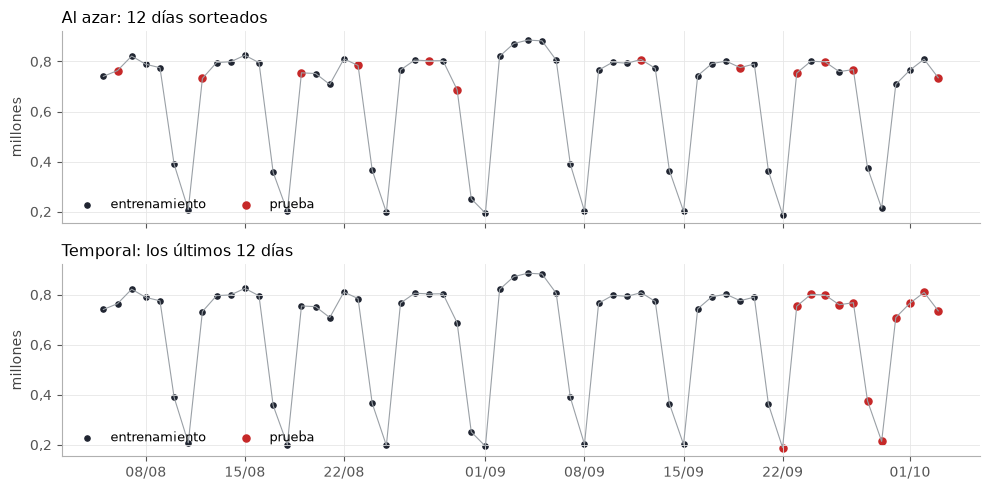

In [4]:
tramo = total.loc["2024-08-05":"2024-10-03"]
rng = np.random.default_rng(1)
sorteo = np.sort(rng.choice(len(tramo), 12, replace=False))

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
for ax, prueba, titulo in ((axes[0], sorteo, "Al azar: 12 días sorteados"), (axes[1], np.arange(48, 60), "Temporal: los últimos 12 días")):
    es_prueba = np.isin(np.arange(len(tramo)), prueba)
    ax.plot(tramo.index, tramo.values, color=GRIS, lw=0.8)
    ax.scatter(tramo.index[~es_prueba], tramo[~es_prueba], color=TINTA, s=14, label="entrenamiento")
    ax.scatter(tramo.index[es_prueba], tramo[es_prueba], color=ROJO, s=26, label="prueba")
    ax.set_title(titulo)
    ax.yaxis.set_major_formatter(en_millones)
    ax.set_ylabel("millones")
    ax.legend(loc="lower left", ncol=2)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
fig.tight_layout()

Para medir la diferencia: un gradient boosting que solo conoce el número de día (`t`), el día de la semana y si es feriado, evaluado con las dos particiones sobre el período de entrenamiento.

In [5]:
d = y_tr.to_frame("pax")
d["t"] = np.arange(len(d))
d["dia_semana"] = d.index.day_of_week
d["feriado"] = d.index.isin(no_habiles).astype(int)
X, y = d[["t", "dia_semana", "feriado"]], d["pax"]

def mae(real, pred):
    return np.mean(np.abs(np.asarray(real) - np.asarray(pred)))

Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, random_state=0)
gb = HistGradientBoostingRegressor(random_state=0).fit(Xa, ya)
mae_azar = mae(yb, gb.predict(Xb))

corte = int(len(d) * 0.8)
gb = HistGradientBoostingRegressor(random_state=0).fit(X.iloc[:corte], y.iloc[:corte])
mae_temporal = mae(y.iloc[corte:], gb.predict(X.iloc[corte:]))

print("MAE con partición al azar:", num(mae_azar), "pasajeros por día")
print("MAE con partición temporal (último 20 %):", num(mae_temporal), "pasajeros por día")

MAE con partición al azar: 44.909 pasajeros por día
MAE con partición temporal (último 20 %): 94.904 pasajeros por día


Con la partición al azar el error parece menor, pero esa cifra no dice cuánto se va a equivocar el modelo con días que todavía no ocurrieron.

## 2. Pronósticos de referencia

Antes de ajustar un modelo conviene saber cuánto se equivocan reglas simples: un modelo más complejo se justifica si se equivoca menos que ellas.

- **Ingenuo**: repite el último dato (sábado 31 de mayo) en los 28 días.
- **Ingenuo estacional**: repite la última semana.
- **Promedio de 4 semanas**: para cada día de la semana, el promedio de ese día en las últimas cuatro semanas.

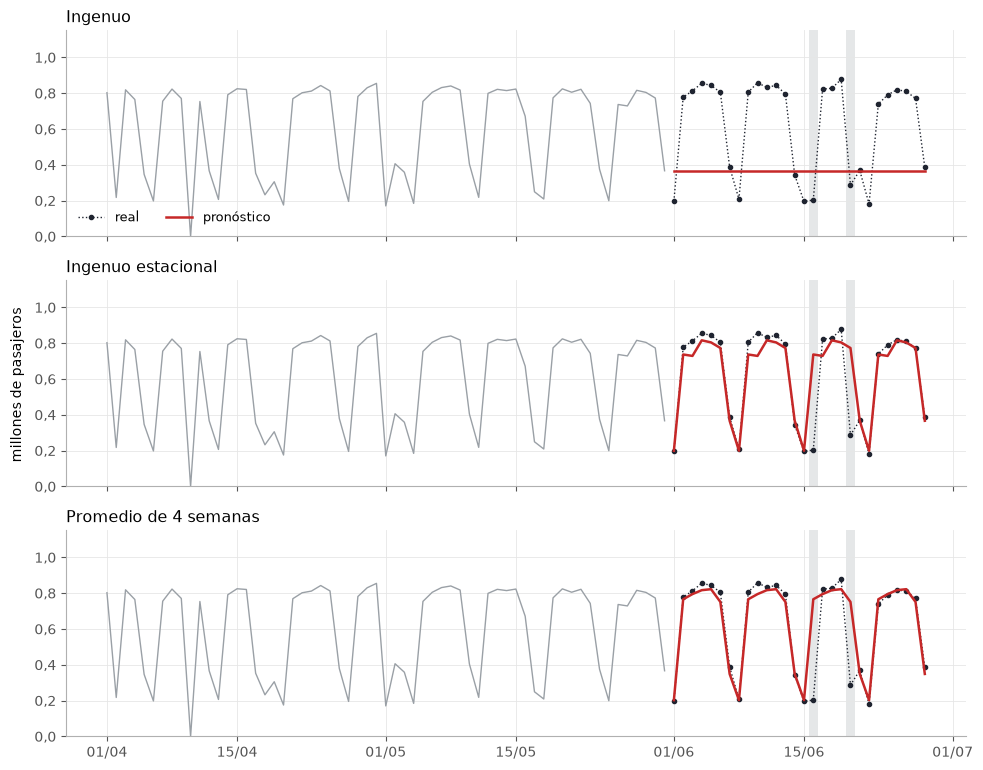

In [6]:
pos = np.arange(h) % 7      # posición dentro de la semana; 0 es el mismo día de la semana que el 1/6
pronosticos = {
    "Ingenuo": np.repeat(y_tr.iloc[-1], h),
    "Ingenuo estacional": np.array([y_tr.iloc[-7 + i] for i in pos]),
    "Promedio de 4 semanas": np.array([np.mean([y_tr.iloc[-7 * w + i] for w in (1, 2, 3, 4)]) for i in pos]),
}

def graficar_pronosticos(preds, desde="2025-04-01", columnas=1, alto=2.6):
    filas = int(np.ceil(len(preds) / columnas))
    fig, axes = plt.subplots(filas, columnas, figsize=(10 if columnas == 1 else 12, alto * filas), sharex=True, sharey=True, squeeze=False)
    hist = total.loc[desde:TRAIN_HASTA]
    for ax, (nombre, p) in zip(axes.flat, preds.items()):
        for f in fer_te:
            ax.axvspan(f - pd.Timedelta(hours=12), f + pd.Timedelta(hours=12), color=GRIS, alpha=0.25, lw=0)
        ax.plot(hist.index, hist.values, color=GRIS, lw=1)
        ax.plot(y_te.index, y_te.values, color=TINTA, lw=1, ls=":", marker="o", ms=3, label="real")
        ax.plot(y_te.index, p, color=ROJO, lw=1.8, label="pronóstico")
        ax.set_title(nombre)
        ax.yaxis.set_major_formatter(en_millones)
        ax.set_ylim(0, 1.15e6)
    for ax in axes.flat[len(preds):]:
        ax.set_visible(False)
    axes.flat[0].legend(loc="lower left", ncol=2)
    axes.flat[0].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    fig.supylabel("millones de pasajeros", fontsize=10)
    fig.tight_layout()

graficar_pronosticos(pronosticos)

Las bandas grises son los feriados de la prueba. Ninguna de las tres referencias los conoce.

## 3. Métricas

Con $e_t = y_t - \hat y_t$ (real menos pronóstico):

$$\mathrm{MAE} = \frac{1}{n}\sum |e_t| \qquad \mathrm{RMSE} = \sqrt{\frac{1}{n}\sum e_t^2} \qquad \mathrm{MAPE} = \frac{100}{n}\sum \left|\frac{e_t}{y_t}\right|$$

El MAE y el RMSE están en pasajeros por día; el RMSE pesa más los errores grandes. El MAPE está en porcentaje del valor real, lo que permite comparar series de distinta escala, pero se dispara cuando el valor real es cercano a cero.

In [7]:
def metricas(real, pred):
    real, pred = np.asarray(real, float), np.asarray(pred, float)
    ok = ~np.isnan(real)
    e = real[ok] - pred[ok]
    return {"MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e ** 2)), "MAPE": 100 * np.mean(np.abs(e) / real[ok])}

def tabla_metricas(preds):
    t = pd.DataFrame({n: metricas(y_te, p) for n, p in preds.items()}).T.sort_values("MAPE")
    return t.round({"MAE": 0, "RMSE": 0, "MAPE": 1})

tabla_metricas(pronosticos)

,MAE,RMSE,MAPE
Promedio de 4 semanas,59094.0,140810.0,19.5
Ingenuo estacional,67311.0,143660.0,20.0
Ingenuo,324360.0,368701.0,52.5


Un día de paro muestra la diferencia entre las tres. Simulamos que el miércoles 11 de junio viajó el 3 % de lo normal y recalculamos las métricas del ingenuo estacional.

In [8]:
real_paro = y_te.copy()
real_paro.loc["2025-06-11"] *= 0.03
p = pronosticos["Ingenuo estacional"]
antes, despues = metricas(y_te, p), metricas(real_paro, p)
pd.DataFrame({"sin paro": antes, "con paro simulado": despues, "cociente": {k: despues[k] / antes[k] for k in antes}}).round(2)

,sin paro,con paro simulado,cociente
MAE,67311.25,94971.36,1.41
RMSE,143659.94,207274.29,1.44
MAPE,20.04,133.12,6.64


Un solo día cambia poco el MAE, bastante más el RMSE (por el cuadrado) y mucho el MAPE: ese día el error es varias veces el valor real.

## 4. Suavizado exponencial

- **Simple**: un nivel que se actualiza con cada dato, $\ell_t = \alpha y_t + (1-\alpha)\ell_{t-1}$. Con $\alpha$ cerca de 1 el nivel sigue el último dato; cerca de 0, promedia mucho pasado. El pronóstico es una recta horizontal.
- **Holt**: agrega una tendencia que se actualiza con $\beta$.
- **Holt-Winters**: agrega un ciclo (acá, semanal) que se actualiza con $\gamma$.

`ExponentialSmoothing` de statsmodels estima $\alpha$, $\beta$ y $\gamma$ minimizando el error de pronóstico a un paso en el entrenamiento.

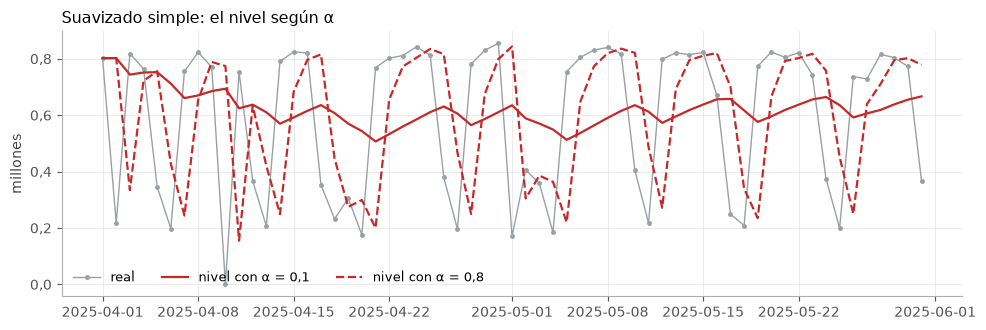

In [9]:
corto = y_tr.loc["2025-04-01":]
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(corto.index, corto.values, color=GRIS, lw=1, marker="o", ms=2.5, label="real")
for alfa, estilo in ((0.1, "-"), (0.8, "--")):
    ajuste = ExponentialSmoothing(corto, initialization_method="known", initial_level=corto.iloc[0]).fit(smoothing_level=alfa, optimized=False)
    ax.plot(corto.index, ajuste.fittedvalues, color=ROJO, ls=estilo, lw=1.6, label=f"nivel con α = {num(alfa, 1)}")
ax.yaxis.set_major_formatter(en_millones)
ax.set_ylabel("millones")
ax.set_title("Suavizado simple: el nivel según α")
ax.legend(loc="lower left", ncol=3)
fig.tight_layout()

In [10]:
modelos_es = {
    "Suavizado simple": ExponentialSmoothing(y_tr, initialization_method="estimated"),
    "Holt": ExponentialSmoothing(y_tr, trend="add", initialization_method="estimated"),
    "Holt-Winters": ExponentialSmoothing(y_tr, trend="add", seasonal="add", seasonal_periods=7, initialization_method="estimated"),
}
parametros = {}
for nombre, m in modelos_es.items():
    ajuste = m.fit()
    pronosticos[nombre] = ajuste.forecast(h).values
    parametros[nombre] = {k: ajuste.params[k] for k in ("smoothing_level", "smoothing_trend", "smoothing_seasonal")}
pd.DataFrame(parametros).T.rename(columns={"smoothing_level": "α", "smoothing_trend": "β", "smoothing_seasonal": "γ"}).round(3)

,α,β,γ
Suavizado simple,0.049,NaN,NaN
Holt,0.052,0.0,NaN
Holt-Winters,0.133,0.0,0.071


Mejor referencia: Promedio de 4 semanas (19,5 %); Holt-Winters: 27,9 %


,MAE,RMSE,MAPE
Promedio de 4 semanas,59094.0,140810.0,19.5
Ingenuo estacional,67311.0,143660.0,20.0
Holt-Winters,90708.0,150627.0,27.9
Ingenuo,324360.0,368701.0,52.5
Suavizado simple,249319.0,265098.0,67.7
Holt,246419.0,265277.0,68.4


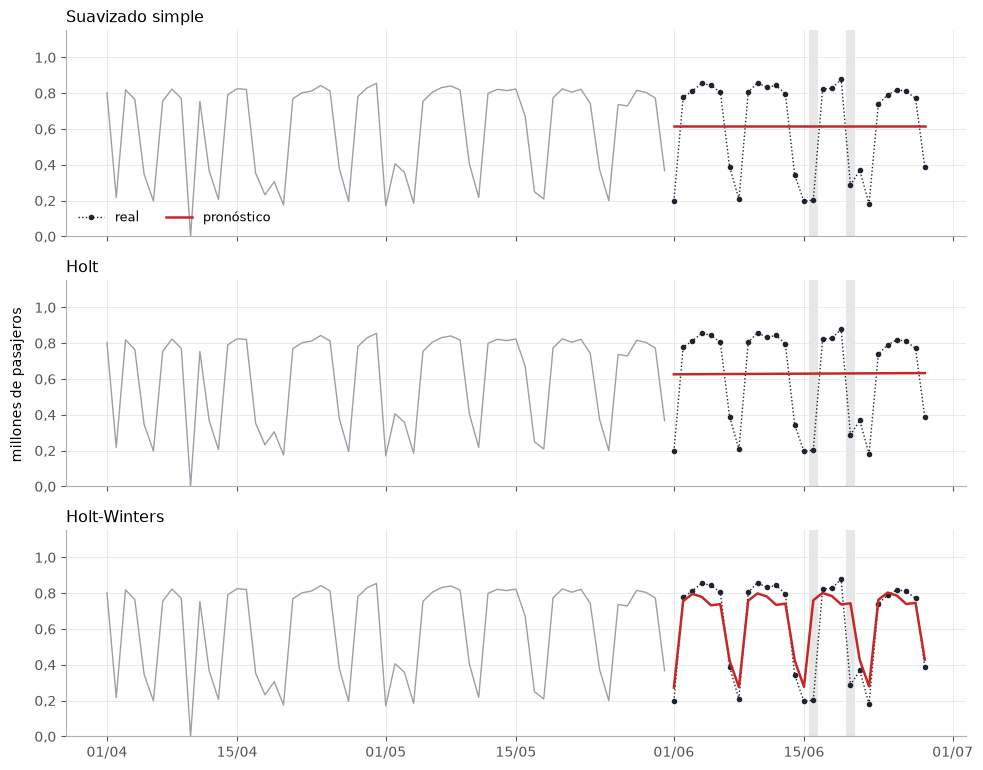

In [11]:
graficar_pronosticos({k: pronosticos[k] for k in modelos_es})
t = tabla_metricas(pronosticos)
mejor_ref = t.loc[["Ingenuo", "Ingenuo estacional", "Promedio de 4 semanas"], "MAPE"].idxmin()
print(f"Mejor referencia: {mejor_ref} ({num(t.loc[mejor_ref, 'MAPE'], 1)} %); Holt-Winters: {num(t.loc['Holt-Winters', 'MAPE'], 1)} %")
t

El suavizado simple y Holt no tienen ciclo semanal: pronostican una recta, y quedan entre los días hábiles y los fines de semana. Holt-Winters tiene el ciclo, pero no sabe de feriados.

## 5. Validación con origen móvil

Un solo período de prueba es una sola muestra: junio de 2025 tiene dos feriados, otro mes puede no tener ninguno. La validación con **origen móvil** repite el ejercicio con varias fechas de corte: se entrena con lo anterior a cada corte y se evalúa en los días siguientes. El error de validación es el promedio.

`TimeSeriesSplit` de scikit-learn arma esas particiones sobre las posiciones de la serie:

In [12]:
tscv = TimeSeriesSplit(n_splits=5, test_size=28)
for i, (idx_tr, idx_te) in enumerate(tscv.split(y_tr), 1):
    print(f"Partición {i}: entrena del {y_tr.index[idx_tr[0]].date()} al {y_tr.index[idx_tr[-1]].date()} ({len(idx_tr)} días),"
          f" prueba del {y_tr.index[idx_te[0]].date()} al {y_tr.index[idx_te[-1]].date()}")

Partición 1: entrena del 2023-01-01 al 2025-01-11 (742 días), prueba del 2025-01-12 al 2025-02-08
Partición 2: entrena del 2023-01-01 al 2025-02-08 (770 días), prueba del 2025-02-09 al 2025-03-08
Partición 3: entrena del 2023-01-01 al 2025-03-08 (798 días), prueba del 2025-03-09 al 2025-04-05
Partición 4: entrena del 2023-01-01 al 2025-04-05 (826 días), prueba del 2025-04-06 al 2025-05-03
Partición 5: entrena del 2023-01-01 al 2025-05-03 (854 días), prueba del 2025-05-04 al 2025-05-31


Con un bucle propio se elige el corte por fecha: el último día de cada mes entre junio de 2024 y abril de 2025, prueba de 28 días. En cada corte se recalculan el ingenuo estacional y Holt-Winters.

Acá conviene el MAE y no el MAPE: la prueba que empieza el 1/4/2025 incluye el paro general del 10/4/2025, en el que no funcionó ninguna línea ([Infobae, 10/4/2025](https://www.infobae.com/sociedad/2025/04/10/empezo-el-paro-general-de-la-cgt-el-transporte-y-todos-los-servicios-afectados-hoy-10-de-abril/)). Con casi cero pasajeros ese día, el MAPE de esa partición se dispara y domina el promedio.

In [13]:
filas = []
for corte in pd.date_range("2024-07-01", "2025-05-01", freq="MS") - pd.Timedelta(days=1):   # último día de cada mes
    hist = total.loc[TRAIN_DESDE:corte].interpolate("time")
    futuro = total.loc[corte + pd.Timedelta(days=1):corte + pd.Timedelta(days=28)]
    p_est = np.array([hist.iloc[-7 + i] for i in np.arange(28) % 7])
    hw = ExponentialSmoothing(hist, trend="add", seasonal="add", seasonal_periods=7, initialization_method="estimated").fit()
    n_fer = sum(d in no_habiles for d in futuro.index)
    filas.append({"corte": corte.date(), "feriados en la prueba": n_fer,
                  "Ingenuo estacional": metricas(futuro, p_est)["MAE"],
                  "Holt-Winters": metricas(futuro, hw.forecast(28).values)["MAE"]})
origen = pd.DataFrame(filas).set_index("corte")
for k in ("Ingenuo estacional", "Holt-Winters"):
    print(f"MAE promedio, {k}: {num(origen[k].mean())} pasajeros por día")
origen.round(0)

MAE promedio, Ingenuo estacional: 89.642 pasajeros por día
MAE promedio, Holt-Winters: 93.605 pasajeros por día


,feriados en la prueba,Ingenuo estacional,Holt-Winters
corte,,,
2024-06-30,1,72523.0,103448.0
2024-07-31,1,69360.0,61894.0
2024-08-31,0,47565.0,45922.0
2024-09-30,2,46722.0,56735.0
2024-10-31,1,178658.0,170036.0
2024-11-30,2,76894.0,77388.0
2024-12-31,1,132263.0,76771.0
2025-01-31,0,60221.0,82206.0
2025-02-28,3,117901.0,116357.0


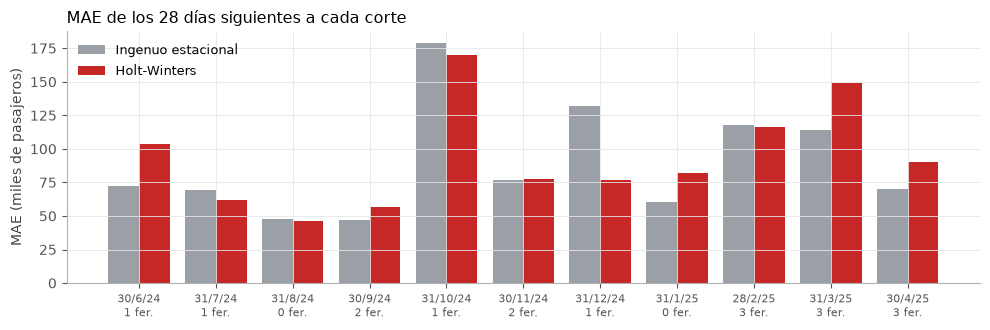

In [14]:
fig, ax = plt.subplots(figsize=(10, 3.4))
x = np.arange(len(origen))
ax.bar(x - 0.2, origen["Ingenuo estacional"], width=0.4, color=GRIS, label="Ingenuo estacional")
ax.bar(x + 0.2, origen["Holt-Winters"], width=0.4, color=ROJO, label="Holt-Winters")
ax.yaxis.set_major_formatter(en_miles)
ax.set_xticks(x, [f"{c.day}/{c.month}/{str(c.year)[2:]}\n{n} fer." for c, n in zip(origen.index, origen["feriados en la prueba"])], fontsize=8)
ax.set_ylabel("MAE (miles de pasajeros)")
ax.set_title("MAE de los 28 días siguientes a cada corte")
ax.legend(loc="upper left")
fig.tight_layout()

El error cambia mucho de un corte a otro. Pesan los feriados de cada prueba y también lo que pasó justo antes del corte: el ingenuo estacional repite la última semana tal cual, así que un día raro en esa semana se repite cuatro veces. Es lo que pasa con el corte del 31/10/2024: ese jueves los datos tienen cerca del 5 % de un día normal (ver `eventos_verificados.csv`) y los cuatro jueves de noviembre se pronostican casi vacíos. Con un solo período de prueba, la cifra depende mucho del período elegido.

## 6. El pronóstico de febrero de 2020

Holt-Winters aditivo de período 7, entrenado con los dos años anteriores a cada corte (un domingo por semana, de octubre de 2019 a mayo de 2020), pronosticando seis semanas. El aislamiento obligatorio rige desde el 20/3/2020 (DNU 297/2020, [Boletín Oficial](https://www.boletinoficial.gob.ar/detalleAviso/primera/227042/20200320)).

In [15]:
H = 42
AISLAMIENTO = pd.Timestamp("2020-03-20")
cortes = pd.date_range("2019-10-06", "2020-05-31", freq="7D")
resultados = {}
for c in cortes:
    hist = total.loc[c - pd.Timedelta(days=729):c].interpolate("time")
    ajuste = ExponentialSmoothing(hist, trend="add", seasonal="add", seasonal_periods=7, initialization_method="estimated").fit()
    pred = ajuste.forecast(H)
    real = total.loc[pred.index]
    resultados[c] = {"pred": pred, "MAPE": metricas(real, pred)["MAPE"], "α": ajuste.params["smoothing_level"],
                     "β": ajuste.params["smoothing_trend"], "γ": ajuste.params["smoothing_seasonal"]}
print(len(cortes), "cortes")

35 cortes


Corte del 16/2: desde el 20/3 viajaron en promedio 15.445 personas por día; el pronóstico promediaba 697.850.


Corte del 5/4: α = 0,18, β = 0,00, γ = 0,05; pronósticos negativos en 12 de 42 días.


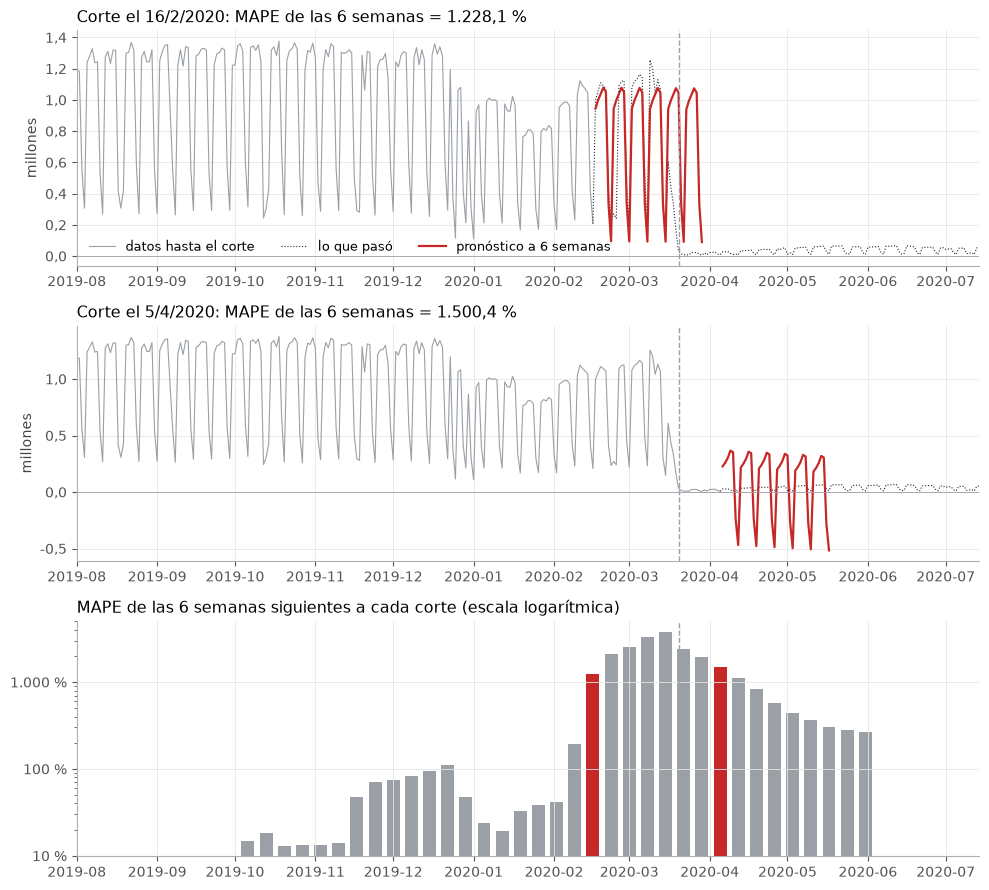

In [16]:
def panel_corte(ax, c):
    r = resultados[c]
    vista = total.loc["2019-08-01":"2020-07-14"]
    ax.plot(vista.loc[:c].index, vista.loc[:c].values, color=GRIS, lw=0.8, label="datos hasta el corte")
    ax.plot(vista.loc[c:].index, vista.loc[c:].values, color=TINTA, lw=0.8, ls=":", label="lo que pasó")
    ax.plot(r["pred"].index, r["pred"].values, color=ROJO, lw=1.6, label="pronóstico a 6 semanas")
    ax.axvline(AISLAMIENTO, color=GRIS, ls="--", lw=1)
    ax.axhline(0, color=GRIS, lw=0.6)
    ax.yaxis.set_major_formatter(en_millones)
    ax.set_ylabel("millones")
    ax.set_title(f"Corte el {c.day}/{c.month}/{c.year}: MAPE de las 6 semanas = {num(r['MAPE'], 1)} %")

c1, c2 = pd.Timestamp("2020-02-16"), pd.Timestamp("2020-04-05")
fig, axes = plt.subplots(3, 1, figsize=(10, 9))
panel_corte(axes[0], c1)
panel_corte(axes[1], c2)
axes[0].legend(loc="lower left", ncol=3)
mapes = pd.Series({c: r["MAPE"] for c, r in resultados.items()})
axes[2].bar(mapes.index, mapes.values, width=5, color=[ROJO if c in (c1, c2) else GRIS for c in mapes.index])
axes[2].set_yscale("log")
axes[2].yaxis.set_major_formatter(FuncFormatter(lambda v, _: num(v) + " %"))
axes[2].axvline(AISLAMIENTO, color=GRIS, ls="--", lw=1)
axes[2].set_title("MAPE de las 6 semanas siguientes a cada corte (escala logarítmica)")
for ax in axes:
    ax.set_xlim(pd.Timestamp("2019-08-01"), pd.Timestamp("2020-07-14"))
fig.tight_layout()

post = resultados[c1]["pred"].loc[AISLAMIENTO:]
print(f"Corte del 16/2: desde el 20/3 viajaron en promedio {num(total.loc[post.index].mean())} personas por día; el pronóstico promediaba {num(post.mean())}.")
r2 = resultados[c2]
print(f"Corte del 5/4: α = {num(r2['α'], 2)}, β = {num(r2['β'], 2)}, γ = {num(r2['γ'], 2)}; pronósticos negativos en {int((r2['pred'] < 0).sum())} de {H} días.")

Con los cortes de octubre a enero, el error depende sobre todo de qué feriados caen en las seis semanas siguientes (con Navidad y Año Nuevo en la prueba, el MAPE sube). Con el corte del 16 de febrero las seis semanas ya incluyen el aislamiento, y no hay forma de anticiparlo: ningún dato hasta ese día lo contiene. Después del 20 de marzo, el ciclo semanal estimado con dos años de datos normales sigue restando cientos de miles de pasajeros los fines de semana a un nivel que ya es muy bajo, y el pronóstico puede quedar por debajo de cero.

## 7. Intervalos de predicción

Un pronóstico puntual no dice cuánto puede equivocarse. Los modelos de espacio de estados (`ETSModel` de statsmodels, la versión estadística del suavizado exponencial) dan intervalos de predicción: un intervalo del 80 % debería contener al valor real en 8 de cada 10 días, si el modelo describe bien la serie.

El intervalo contiene al real en 26 de 28 días.
Días afuera: ['16/6 (lun)', '20/6 (vie)']
Ancho del intervalo: 363.701 el primer día y 467.046 el día 28.


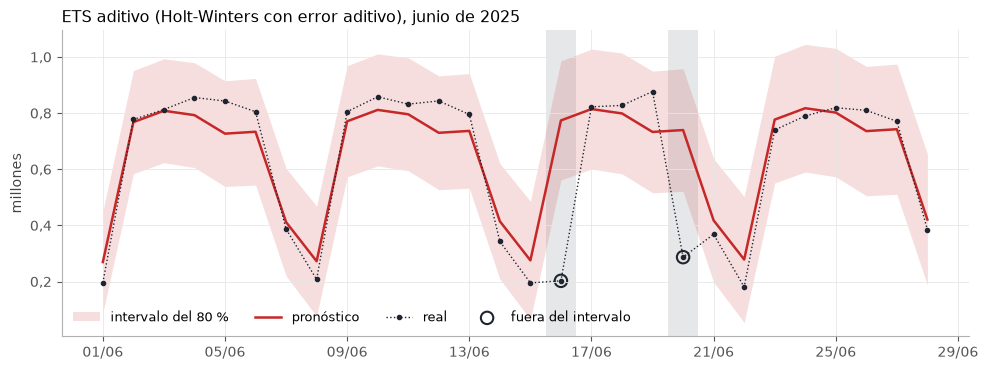

In [17]:
ets = ETSModel(y_tr, error="add", trend="add", seasonal="add", seasonal_periods=7).fit(disp=False)
banda = ets.get_prediction(start=TEST_DESDE, end=TEST_HASTA).summary_frame(alpha=0.2)
afuera = (y_te < banda["pi_lower"]) | (y_te > banda["pi_upper"])
ancho = banda["pi_upper"] - banda["pi_lower"]

fig, ax = plt.subplots(figsize=(10, 3.8))
for f in fer_te:
    ax.axvspan(f - pd.Timedelta(hours=12), f + pd.Timedelta(hours=12), color=GRIS, alpha=0.25, lw=0)
ax.fill_between(banda.index, banda["pi_lower"], banda["pi_upper"], color=ROJO, alpha=0.15, lw=0, label="intervalo del 80 %")
ax.plot(banda.index, banda["mean"], color=ROJO, lw=1.8, label="pronóstico")
ax.plot(y_te.index, y_te.values, color=TINTA, ls=":", marker="o", ms=3, lw=1, label="real")
ax.scatter(y_te.index[afuera], y_te[afuera], s=80, facecolors="none", edgecolors=TINTA, lw=1.5, label="fuera del intervalo")
ax.yaxis.set_major_formatter(en_millones)
ax.set_ylabel("millones")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.set_title("ETS aditivo (Holt-Winters con error aditivo), junio de 2025")
ax.legend(loc="lower left", ncol=4)
fig.tight_layout()

print(f"El intervalo contiene al real en {int((~afuera).sum())} de {h} días.")
print("Días afuera:", [f"{d.day}/{d.month} ({DIAS3[d.day_of_week]})" for d in y_te.index[afuera]])
print(f"Ancho del intervalo: {num(ancho.iloc[0])} el primer día y {num(ancho.iloc[-1])} el día {h}.")

El intervalo se ensancha con el horizonte: cuanto más lejos, más incertidumbre se acumula. Los días que quedan afuera son, sobre todo, los feriados: el modelo no tiene forma de saber que esos días son distintos. En el cuaderno 05 se agregan variables externas para eso.

## Para seguir

1. Repetir la comparación de la sección 4 con julio de 2025 como prueba (incluye las vacaciones de invierno). ¿Cambia el orden de los modelos?
2. Ajustar Holt-Winters con ciclo multiplicativo (`seasonal="mul"`) o sobre el logaritmo de la serie y comparar el MAPE con el aditivo, en junio de 2025 y con origen móvil.
3. Cambiar el horizonte del origen móvil a 7 días. ¿Cuánto baja el error? ¿Sigue ganando el mismo modelo?